# Rectified Flow 与 Reflow：让生成轨迹变直、让采样变快

本 notebook 用二维双月形分布完整复现 Rectified Flow 的核心实验。重点不是只看最终生成样本，而是逐轮观察 Reflow 如何改变噪声与数据之间的耦合，以及这种变化如何降低 ODE 轨迹弯曲程度和少步 Euler 误差。

实验依次验证：

1. 第一轮 Rectified Flow 如何从独立端点配对学习速度场；
2. 条件直线插值和学习 ODE 在中间时刻具有近似相同的边缘分布；
3. Reflow 如何用上一轮 ODE 的起点和终点构造新耦合；
4. 四轮训练后 ODE 轨迹是否变直、输运代价是否下降；
5. 轨迹变直后，1、2、4、8、16 步 Euler 是否更接近高精度 RK4；
6. 少步积分是否仍能保持双月形生成分布。

> 环境：`conda activate pytorch`。代码自动使用 CUDA，并固定随机种子以便复现。

## 1. Rectified Flow 目标

设初始噪声和目标数据为

$$
X_0\sim\pi_0,\qquad X_1\sim\pi_1,
$$

并由当前耦合 $\gamma_k$ 提供端点配对 $(X_0,X_1)$。训练时只使用端点间的条件直线

$$
X_t=(1-t)X_0+tX_1,
\qquad \dot X_t=X_1-X_0,
$$

速度网络的回归目标为

$$
\mathcal L_k(\theta)=
\mathbb E_{(X_0,X_1)\sim\gamma_k,\,t\sim U(0,1)}
\left\|v_\theta(X_t,t)-(X_1-X_0)\right\|^2.
$$

平方损失的最优解是条件速度的后验平均。用该速度场求解

$$
\frac{dZ_t}{dt}=v_\theta(Z_t,t),\qquad Z_0\sim\pi_0,
$$

可得到与条件插值近似相同的边缘概率路径，但单条 ODE 轨迹一般不是训练时的随机配对直线。

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("rectified_flow_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

ROUNDS = 4
TRAIN_STEPS = 2_500
N_PAIRS = 12_000
BATCH_SIZE = 1_024
REFERENCE_STEPS = 100
EVAL_SAMPLES = 1_200

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Rounds: {ROUNDS}, training steps per round: {TRAIN_STEPS}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Rounds: 4, training steps per round: 2500
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/rectified_flow_outputs


## 2. 初始分布与双月形目标分布

初始分布为二维标准高斯，目标分布为带少量噪声的双月形：

$$
X_0\sim\mathcal N(0,I_2),\qquad X_1\sim p_{\mathrm{moons}}.
$$

第一轮使用独立耦合 $\gamma_0=\pi_0\otimes\pi_1$，因此每个噪声点与目标点之间的配对是随机的。

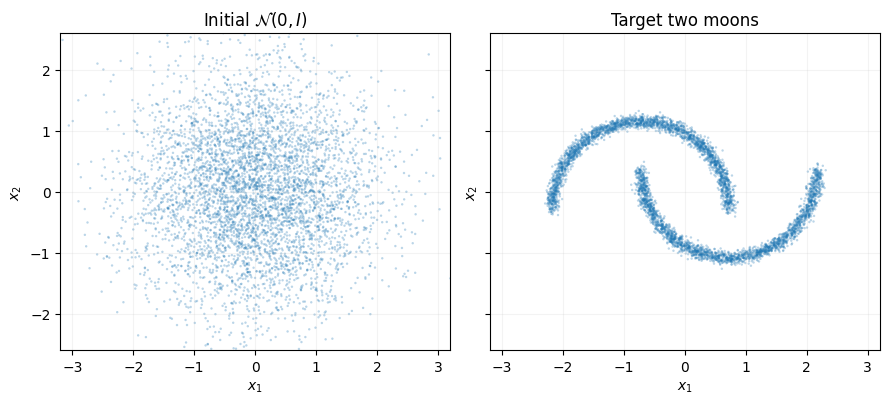

In [2]:
def sample_moons(n):
    angle = torch.rand(n, device=DEVICE)*math.pi
    branch = torch.randint(0, 2, (n,), device=DEVICE)
    upper = torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)
    lower = torch.stack([1-torch.cos(angle), 0.45-torch.sin(angle)], dim=1)
    points = torch.where(branch[:, None] == 0, upper, lower)
    shift = torch.tensor([0.5, 0.2], device=DEVICE)
    return (points-shift)*1.45+0.055*torch.randn(n, 2, device=DEVICE)


initial_preview = torch.randn(5_000, 2, device=DEVICE)
target_preview = sample_moons(5_000)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, points, title in zip(axes, [initial_preview, target_preview],
                             [r"Initial $\mathcal{N}(0,I)$", "Target two moons"]):
    p = points.cpu().numpy()
    ax.scatter(p[:, 0], p[:, 1], s=3, alpha=0.3, edgecolors="none")
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-3.2, 3.2), ylim=(-2.6, 2.6))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"01_source_and_target.png", dpi=170, bbox_inches="tight")
plt.show()

## 3. 速度网络与 ODE 求解器

网络输入二维位置和时间，输出二维速度。训练只需要随机时间点上的速度回归，不需要在训练 loss 内求解 ODE。

Reflow 配对和参考轨迹使用 100 步 RK4；少步推理实验使用 Euler，从而直接测量离散化误差。

In [3]:
class VelocityNet(nn.Module):
    def __init__(self, width=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, width), nn.SiLU(),
            nn.Linear(width, width), nn.SiLU(),
            nn.Linear(width, width), nn.SiLU(),
            nn.Linear(width, 2),
        )

    def forward(self, x, t):
        if not isinstance(t, torch.Tensor):
            t = torch.full((len(x), 1), float(t), device=x.device, dtype=x.dtype)
        elif t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]
        return self.net(torch.cat([x, t], dim=1))


@torch.no_grad()
def solve_ode(model, x0, steps=100, method="rk4", keep_path=False):
    x = x0.clone()
    path = [x.clone()] if keep_path else None
    h = 1.0/steps
    for step in range(steps):
        t = step*h
        if method == "euler":
            x = x+h*model(x, t)
        elif method == "rk4":
            k1 = model(x, t)
            k2 = model(x+0.5*h*k1, t+0.5*h)
            k3 = model(x+0.5*h*k2, t+0.5*h)
            k4 = model(x+h*k3, t+h)
            x = x+h*(k1+2*k2+2*k3+k4)/6
        else:
            raise ValueError("method must be 'euler' or 'rk4'")
        if keep_path:
            path.append(x.clone())
    return torch.stack(path) if keep_path else x


def train_velocity(model, pairs, steps=TRAIN_STEPS):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    losses = []
    model.train()
    for step in range(1, steps+1):
        indices = torch.randint(len(pairs), (BATCH_SIZE,), device=DEVICE)
        x0, x1 = pairs[indices, 0], pairs[indices, 1]
        t = torch.rand(BATCH_SIZE, 1, device=DEVICE)
        xt = (1-t)*x0+t*x1
        target_velocity = x1-x0
        loss = (model(xt, t)-target_velocity).square().sum(dim=1).mean()
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if step == 1 or step % 500 == 0:
            print(f"  step {step:4d}/{steps}: loss(100-step avg)={np.mean(losses[-100:]):.6f}")
    model.eval()
    return losses


print(VelocityNet())
print(f"Trainable parameters: {sum(p.numel() for p in VelocityNet().parameters()):,}")

VelocityNet(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 33,794


## 4. Reflow：重新构造端点耦合

第 $k$ 轮模型训练完成后，从新的噪声 $Z_0\sim\pi_0$ 出发求解上一轮 ODE，得到 $Z_1=T_k(Z_0)$，然后定义

$$
\gamma_{k+1}=\operatorname{Law}(Z_0,Z_1).
$$

下一轮仍对新端点做直线插值

$$
Z_t^{\mathrm{linear}}=(1-t)Z_0+tZ_1.
$$

Reflow 保存的是端点配对，不会把上一轮弯曲的 ODE 轨迹当作监督目标。

### 评估指标

轨迹直线性定义为

$$
S_k=\mathbb E\int_0^1
\left\|\dot Z_t-(Z_1-Z_0)\right\|^2dt.
$$

输入耦合的二次输运代价为

$$
C_k=\mathbb E_{\gamma_k}\|X_1-X_0\|^2.
$$

少步 Euler 相对 100 步 RK4 的终点误差为

$$
E_N^{(k)}=\mathbb E\left\|
Z_{1,\mathrm{Euler}(N)}^{(k)}-Z_{1,\mathrm{RK4}}^{(k)}
\right\|^2.
$$

此外使用 Sliced Wasserstein Distance（SWD）比较条件直线插值和 ODE 在 $t=0.25,0.5,0.75$ 的边缘分布。有限网络下该距离不会严格为零，但应较小。

In [4]:
def trajectory_straightness(path):
    finite_difference_velocity = (path[1:]-path[:-1])*(len(path)-1)
    displacement = path[-1]-path[0]
    return (finite_difference_velocity-displacement[None]).square().sum(-1).mean().item()


@torch.no_grad()
def sliced_wasserstein(x, y, projections=64):
    directions = torch.randn(2, projections, device=DEVICE)
    directions /= torch.linalg.vector_norm(directions, dim=0, keepdim=True)
    projected_x = torch.sort(x@directions, dim=0).values
    projected_y = torch.sort(y@directions, dim=0).values
    return (projected_x-projected_y).square().mean().sqrt().item()


@torch.no_grad()
def round_metrics(model, pairs, eval_x0, reference_path):
    reference_endpoint = reference_path[-1]
    result = {
        "straightness": trajectory_straightness(reference_path),
        "cost_l2": (pairs[:, 1]-pairs[:, 0]).square().sum(-1).mean().item(),
        "cost_l1": torch.linalg.vector_norm(pairs[:, 1]-pairs[:, 0], dim=-1).mean().item(),
    }
    for steps in [1, 2, 4, 8, 16]:
        endpoint = solve_ode(model, eval_x0, steps=steps, method="euler")
        result[f"euler_{steps}"] = (endpoint-reference_endpoint).square().sum(-1).mean().item()

    marginal_count = min(2_000, len(pairs))
    marginal_path = solve_ode(model, pairs[:marginal_count, 0],
                              steps=REFERENCE_STEPS, method="rk4", keep_path=True)
    swd_values = []
    for t_value in [0.25, 0.5, 0.75]:
        linear = (1-t_value)*pairs[:marginal_count, 0]+t_value*pairs[:marginal_count, 1]
        ode = marginal_path[round(t_value*REFERENCE_STEPS)]
        swd_values.append(sliced_wasserstein(linear, ode))
    result["marginal_swd"] = float(np.mean(swd_values))
    result["target_swd"] = sliced_wasserstein(reference_endpoint, sample_moons(len(reference_endpoint)))
    return result

## 5. 连续训练四轮 Rectified Flow

下面完整执行 1-RF、2-RF、3-RF、4-RF。每一轮都重新初始化并训练一个速度网络；训练完成后保存模型、参考 ODE 轨迹、输入耦合和所有指标。

In [5]:
source = torch.randn(N_PAIRS, 2, device=DEVICE)
target = sample_moons(N_PAIRS)
pairs = torch.stack([source, target], dim=1)

torch.manual_seed(SEED+100)
eval_x0 = torch.randn(EVAL_SAMPLES, 2, device=DEVICE)

models = []
loss_histories = []
pair_snapshots = []
reference_paths = []
metrics = []

experiment_started = time.perf_counter()
for round_index in range(ROUNDS):
    print(f"\n========== {round_index+1}-RF / {ROUNDS}-RF ==========")
    pair_snapshots.append(pairs.detach().clone())
    model = VelocityNet().to(DEVICE)
    losses = train_velocity(model, pairs)
    reference_path = solve_ode(model, eval_x0, steps=REFERENCE_STEPS,
                               method="rk4", keep_path=True)
    record = round_metrics(model, pairs, eval_x0, reference_path)
    print({key: round(value, 6) for key, value in record.items()})

    models.append(model)
    loss_histories.append(losses)
    reference_paths.append(reference_path.detach())
    metrics.append(record)
    torch.save(model.state_dict(), OUTPUT_DIR/f"rectified_flow_round_{round_index+1}.pt")

    if round_index+1 < ROUNDS:
        new_x0 = torch.randn(N_PAIRS, 2, device=DEVICE)
        new_x1 = solve_ode(model, new_x0, steps=REFERENCE_STEPS, method="rk4")
        pairs = torch.stack([new_x0, new_x1], dim=1)

print(f"\nFour-round experiment finished in {time.perf_counter()-experiment_started:.1f} s")


========== 1-RF / 4-RF ==========


  step    1/2500: loss(100-step avg)=3.807023


  step  500/2500: loss(100-step avg)=2.950450


  step 1000/2500: loss(100-step avg)=2.894497


  step 1500/2500: loss(100-step avg)=2.823669


...

  step 1000/2500: loss(100-step avg)=0.009324


  step 1500/2500: loss(100-step avg)=0.006169


  step 2000/2500: loss(100-step avg)=0.004600


  step 2500/2500: loss(100-step avg)=0.003305


{'straightness': 0.002495, 'cost_l2': 0.48604, 'cost_l1': 0.61279, 'euler_1': 0.005452, 'euler_2': 0.0016, 'euler_4': 0.000517, 'euler_8': 0.000145, 'euler_16': 3.7e-05, 'marginal_swd': 0.007476, 'target_swd': 0.073926}

Four-round experiment finished in 48.9 s


In [6]:
metric_columns = ["straightness", "cost_l2", "cost_l1", "marginal_swd", "target_swd",
                  "euler_1", "euler_2", "euler_4", "euler_8", "euler_16"]
print(f"{'round':>6}"+"".join(f"{name:>15}" for name in metric_columns))
for i, record in enumerate(metrics, 1):
    print(f"{i:6d}"+"".join(f"{record[name]:15.6f}" for name in metric_columns))

 round   straightness        cost_l2        cost_l1   marginal_swd     target_swd        euler_1        euler_2        euler_4        euler_8       euler_16
     1       0.923388       4.145937       1.823964       0.051443       0.113090       2.379353       0.577514       0.186642       0.058755       0.017851
     2       0.004660       0.500201       0.619397       0.009829       0.067663       0.009260       0.002859       0.000984       0.000269       0.000068
     3       0.002624       0.483843       0.609037       0.007658       0.088656       0.005969       0.001838       0.000583       0.000169       0.000043
     4       0.002495       0.486040       0.612790       0.007476       0.073926       0.005452       0.001600       0.000517       0.000145       0.000037


## 6. Reflow 如何改变端点耦合

下图每条线只表示该轮训练所使用的端点配对，并不是 ODE 轨迹。第一轮独立耦合存在大量交叉；后续配对由上一轮确定性 ODE 产生，通常更有结构、距离也更短。

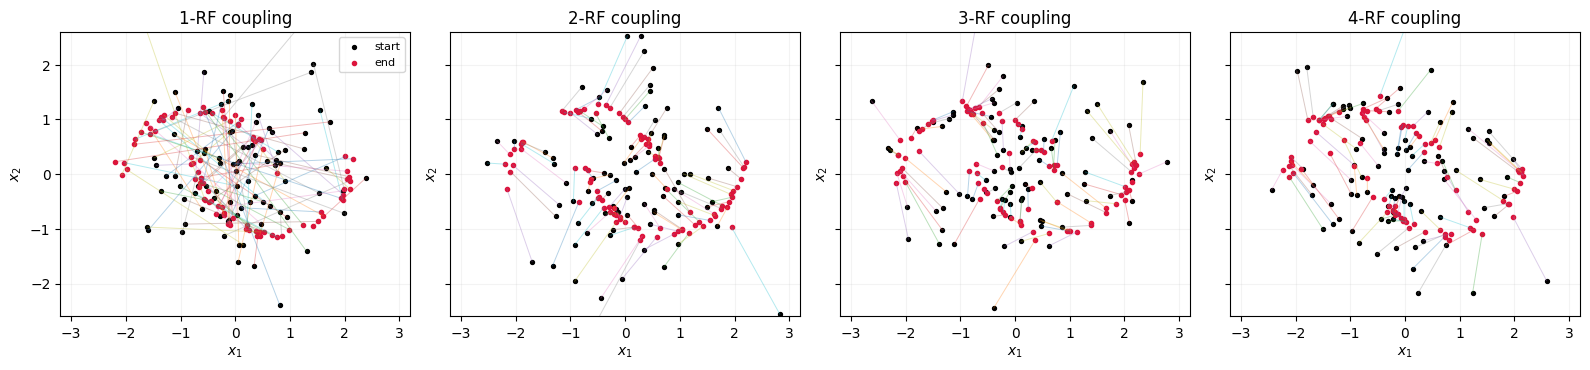

In [7]:
fig, axes = plt.subplots(1, ROUNDS, figsize=(16, 4), sharex=True, sharey=True)
for round_index, (ax, round_pairs) in enumerate(zip(axes, pair_snapshots), 1):
    pair_np = round_pairs[:90].cpu().numpy()
    for start, end in pair_np:
        ax.plot([start[0], end[0]], [start[1], end[1]], lw=0.7, alpha=0.32)
    ax.scatter(pair_np[:, 0, 0], pair_np[:, 0, 1], s=8, c="black", label="start")
    ax.scatter(pair_np[:, 1, 0], pair_np[:, 1, 1], s=9, c="crimson", label="end")
    ax.set(title=f"{round_index}-RF coupling", xlabel="$x_1$", ylabel="$x_2$",
           xlim=(-3.2, 3.2), ylim=(-2.6, 2.6))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"02_reflow_couplings.png", dpi=170, bbox_inches="tight")
plt.show()

## 7. 同一批粒子的 ODE 轨迹

四张图使用完全相同的初始点。第一轮需要弯曲和重新排列粒子；Reflow 后的速度场逐渐接近每对新端点之间的恒定速度，因此轨迹明显变直。

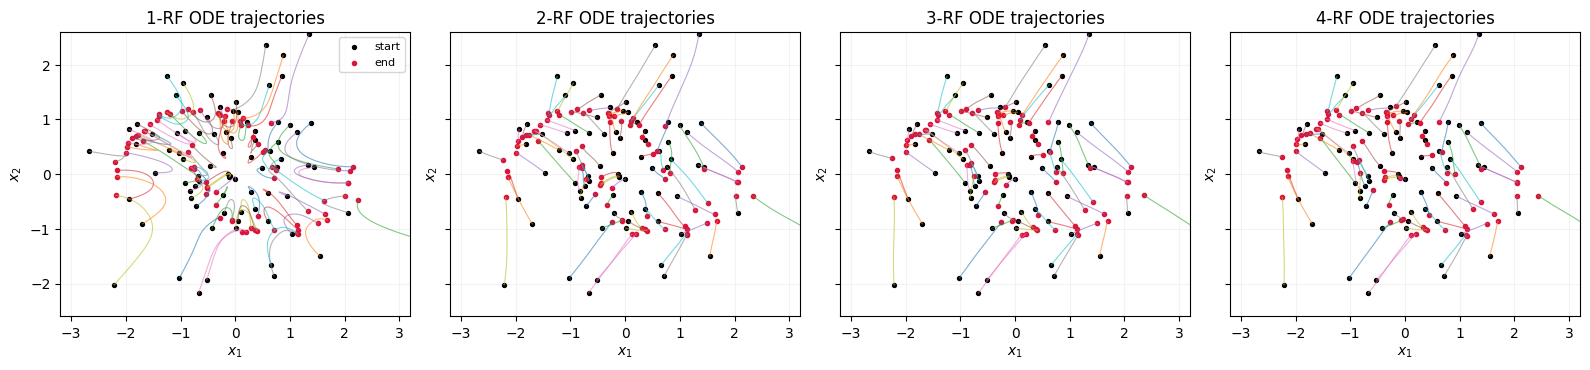

In [8]:
fig, axes = plt.subplots(1, ROUNDS, figsize=(16, 4), sharex=True, sharey=True)
for round_index, (ax, path) in enumerate(zip(axes, reference_paths), 1):
    path_np = path[:, :80].cpu().numpy()
    for particle in range(path_np.shape[1]):
        ax.plot(path_np[:, particle, 0], path_np[:, particle, 1], lw=0.8, alpha=0.58)
    ax.scatter(path_np[0, :, 0], path_np[0, :, 1], s=8, c="black", label="start")
    ax.scatter(path_np[-1, :, 0], path_np[-1, :, 1], s=9, c="crimson", label="end")
    ax.set(title=f"{round_index}-RF ODE trajectories", xlabel="$x_1$", ylabel="$x_2$",
           xlim=(-3.2, 3.2), ylim=(-2.6, 2.6))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_ode_trajectories.png", dpi=170, bbox_inches="tight")
plt.show()

## 8. 边缘分布保持：条件直线与 ODE

理论上的 Rectified Flow 速度会保持条件插值的所有单时刻边缘分布。下面比较第 1 轮和第 4 轮在三个中间时刻的样本：上排来自训练端点的直线插值，下排来自学习速度场的 RK4 ODE。

两排中的单个粒子没有一一对应关系；应比较整体分布形状。表格中的 `marginal_swd` 给出了三个时刻 SWD 的平均值。

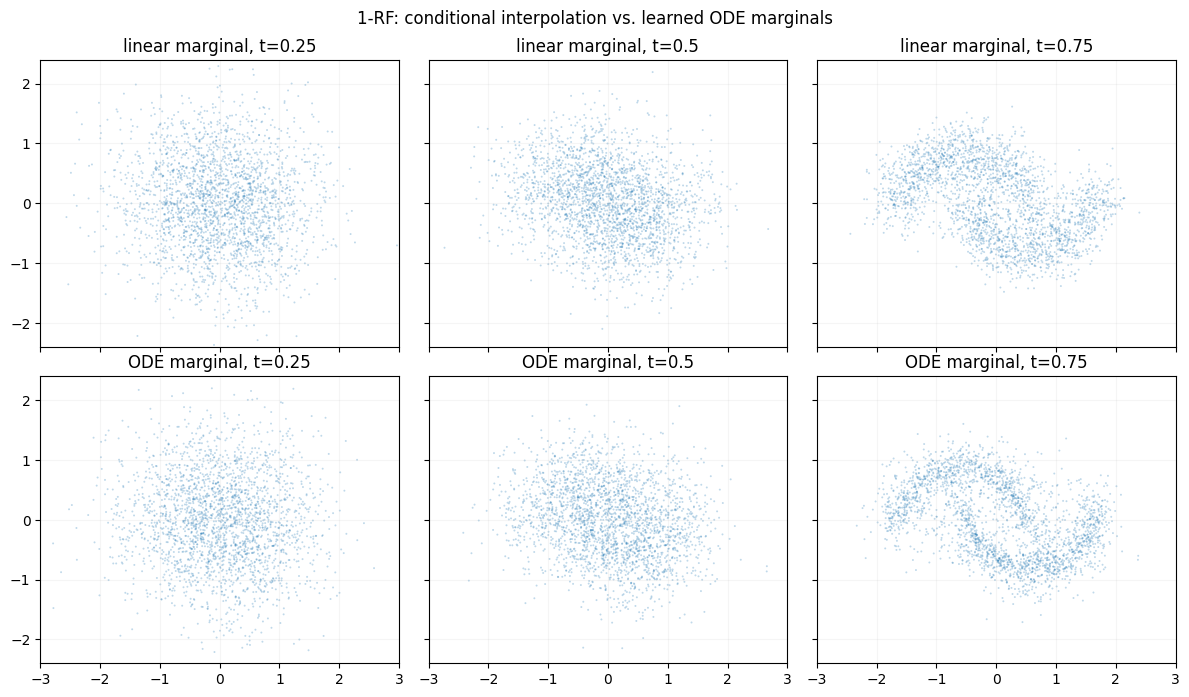

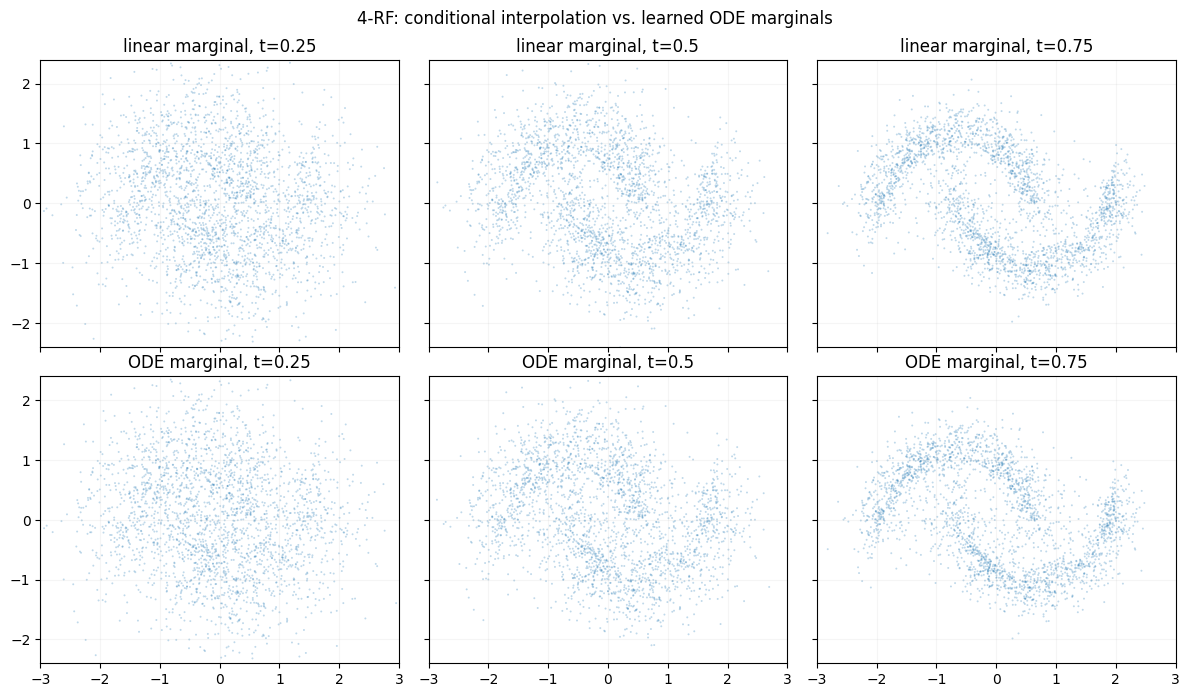

In [9]:
@torch.no_grad()
def plot_marginal_comparison(round_index):
    model = models[round_index]
    round_pairs = pair_snapshots[round_index][:2_500]
    ode_path = solve_ode(model, round_pairs[:, 0], steps=REFERENCE_STEPS,
                         method="rk4", keep_path=True)
    times = [0.25, 0.5, 0.75]
    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
    for column, t_value in enumerate(times):
        linear = (1-t_value)*round_pairs[:, 0]+t_value*round_pairs[:, 1]
        ode = ode_path[round(t_value*REFERENCE_STEPS)]
        for row, (points, label) in enumerate([(linear, "linear marginal"), (ode, "ODE marginal")]):
            p = points.cpu().numpy()
            axes[row, column].scatter(p[:, 0], p[:, 1], s=2.0, alpha=0.28, edgecolors="none")
            axes[row, column].set(title=f"{label}, t={t_value}", xlim=(-3.0, 3.0), ylim=(-2.4, 2.4))
            axes[row, column].set_aspect("equal")
            axes[row, column].grid(alpha=0.12)
    fig.suptitle(f"{round_index+1}-RF: conditional interpolation vs. learned ODE marginals")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/f"04_marginals_round_{round_index+1}.png", dpi=170, bbox_inches="tight")
    plt.show()


plot_marginal_comparison(0)
plot_marginal_comparison(ROUNDS-1)

## 9. 直线性、输运代价与少步积分误差

如果 Reflow 有效，`straightness` 和输入耦合的凸输运代价应显著下降。同时，轨迹越接近直线，低步数 Euler 越容易逼近同一模型的 RK4 解。

Euler 误差只衡量数值积分误差；`target_swd` 另外检查 RK4 生成分布是否仍接近真实双月形目标，避免把“容易积分”误解为“生成质量一定正确”。

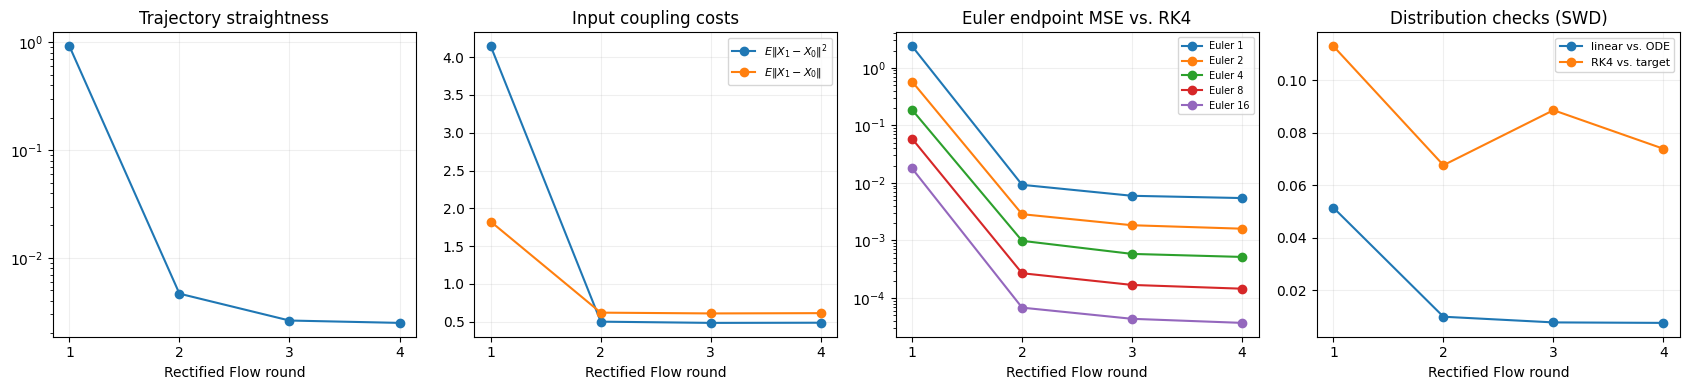

In [10]:
round_axis = np.arange(1, ROUNDS+1)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

axes[0].semilogy(round_axis, [m["straightness"] for m in metrics], "o-")
axes[0].set_title("Trajectory straightness")

axes[1].plot(round_axis, [m["cost_l2"] for m in metrics], "o-", label=r"$E\|X_1-X_0\|^2$")
axes[1].plot(round_axis, [m["cost_l1"] for m in metrics], "o-", label=r"$E\|X_1-X_0\|$")
axes[1].set_title("Input coupling costs")
axes[1].legend(fontsize=8)

for steps in [1, 2, 4, 8, 16]:
    axes[2].semilogy(round_axis, [m[f"euler_{steps}"] for m in metrics], "o-", label=f"Euler {steps}")
axes[2].set_title("Euler endpoint MSE vs. RK4")
axes[2].legend(fontsize=7)

axes[3].plot(round_axis, [m["marginal_swd"] for m in metrics], "o-", label="linear vs. ODE")
axes[3].plot(round_axis, [m["target_swd"] for m in metrics], "o-", label="RK4 vs. target")
axes[3].set_title("Distribution checks (SWD)")
axes[3].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("Rectified Flow round")
    ax.set_xticks(round_axis)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"05_metrics.png", dpi=170, bbox_inches="tight")
plt.show()

## 10. 少步生成的直接对比

最后直接比较 1-RF 与 4-RF 的 Euler 和 RK4 终点。若 Reflow 已将轨迹拉直，4-RF 的 1 步或 4 步 Euler 应比 1-RF 的同等步数更接近其 RK4 结果，同时继续保持双月形结构。

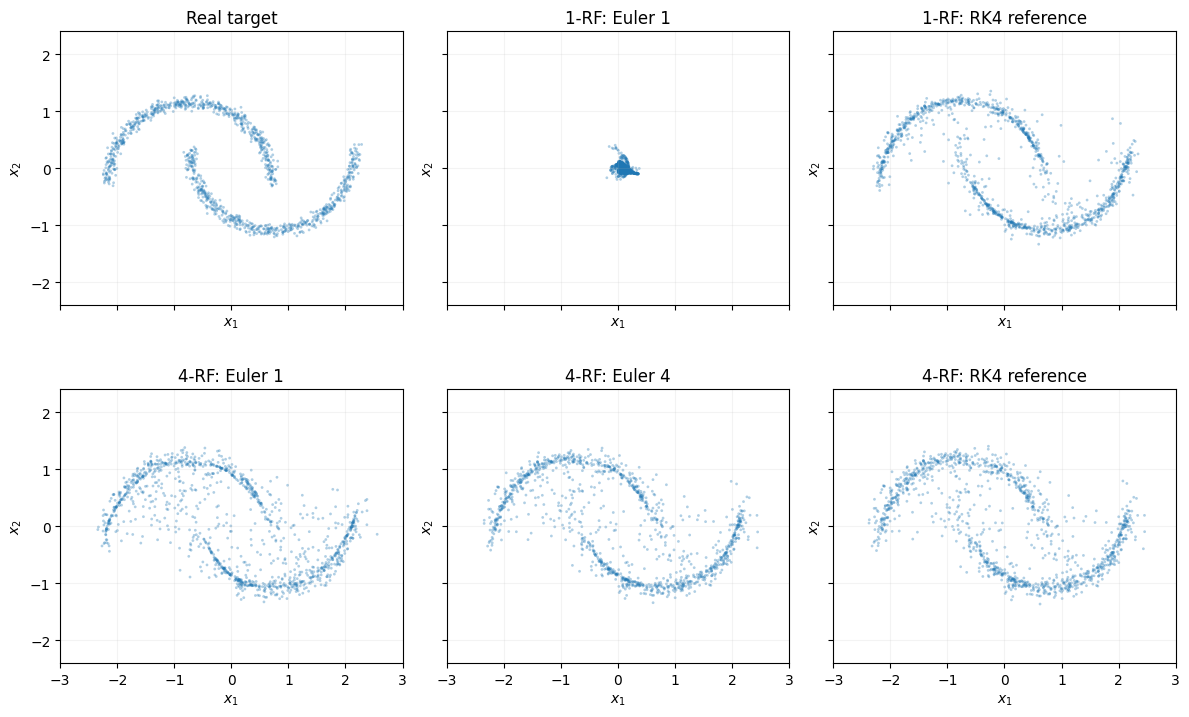

In [11]:
@torch.no_grad()
def generated_endpoint(model, steps, method):
    return solve_ode(model, eval_x0, steps=steps, method=method).cpu().numpy()


generation_panels = [
    (sample_moons(EVAL_SAMPLES).cpu().numpy(), "Real target"),
    (generated_endpoint(models[0], 1, "euler"), "1-RF: Euler 1"),
    (generated_endpoint(models[0], REFERENCE_STEPS, "rk4"), "1-RF: RK4 reference"),
    (generated_endpoint(models[-1], 1, "euler"), "4-RF: Euler 1"),
    (generated_endpoint(models[-1], 4, "euler"), "4-RF: Euler 4"),
    (generated_endpoint(models[-1], REFERENCE_STEPS, "rk4"), "4-RF: RK4 reference"),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, (points, title) in zip(axes.ravel(), generation_panels):
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.35, edgecolors="none")
    ax.set(title=title, xlim=(-3.0, 3.0), ylim=(-2.4, 2.4), xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"06_few_step_generation.png", dpi=170, bbox_inches="tight")
plt.show()

## 11. 结论与读图方法

| 现象 | 应如何解释 |
|---|---|
| 条件配对线逐轮变得更有结构 | Reflow 用上一轮 ODE 的确定性起终点替换独立耦合 |
| ODE 曲线逐轮接近直线 | 后续模型回归的新端点位移更接近恒定速度 |
| `straightness` 与输运代价下降 | 数值上支持 Reflow 的直线化趋势 |
| Euler 相对 RK4 的误差下降 | 更直的轨迹允许更少的函数评估次数 |
| 线性插值与 ODE 的 SWD 较小 | 学习速度近似保持训练概率路径的单时刻边缘 |
| RK4 对目标的 SWD 没有明显恶化 | 直线化没有以明显丢失生成分布为代价 |

有限网络、有限数据和有限训练步数下，各项指标不必每轮严格单调。最关键的判断是：第一轮 Reflow 后轨迹弯曲程度与低步数积分误差是否出现数量级下降，同时高精度生成结果仍覆盖双月形目标。